# glowfinder — exploration

The narrative version of the pipeline, for the write-up. Every number here comes from the same
modules `uv run glowfinder-pipeline` runs; run that first so `data/raw/` is populated.

1. Clean the Sarkisyan 2016 landscape (+2 offset, validated against the construct).
2. How narrow is the peak?
3. Which zero-shot models carry signal on GFP?
4. The offline bake-off: do the strategies separate before any UI exists?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from glowfinder_pipeline import bakeoff, clean, download, esm_score, evolution, reference
from glowfinder_pipeline.constants import RAW_DIR, VISIBLE_THRESHOLD

paths = {k: RAW_DIR / s.filename for k, s in download.SOURCES.items()}
ref = reference.build_reference(paths["uniprot_p42212"], paths["sarkisyan_reference_dna"], paths["alphafold_p42212"])
wt = ref["sequence"]
print("construct vs P42212:", ref["constructDifferences"])
df = clean.clean(paths["sarkisyan_aa_genotypes"], wt)
print(f"{len(df):,} genotypes parsed; the +2 offset assertion held for every mutation")

Matplotlib is building the font cache; this may take a moment.


construct vs P42212: [{'position': 64, 'uniprot': 'F', 'construct': 'L'}]


54,025 genotypes parsed; the +2 offset assertion held for every mutation


## 2. How narrow is the peak?

Brightness is log10. Above ~2.5 the protein visibly glows; the dark mode sits near 1.3.

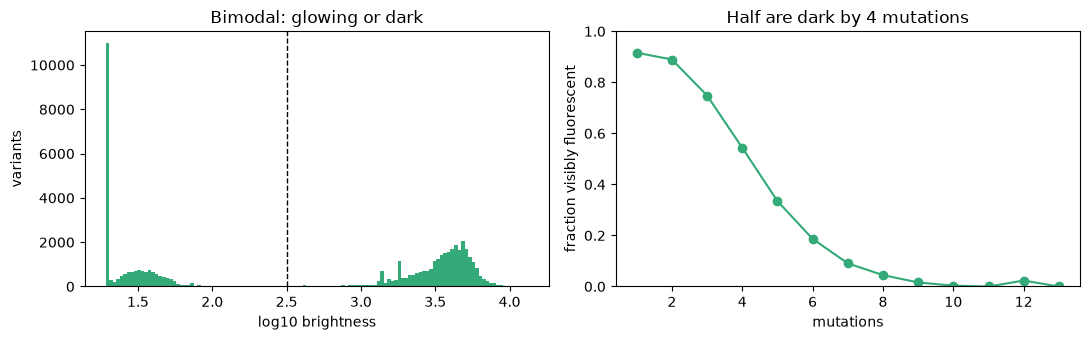

In [2]:
shipped = df[~df.has_stop]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(shipped.median_log_brightness, bins=120, color="#3a7")
axes[0].axvline(VISIBLE_THRESHOLD, color="k", ls="--", lw=1)
axes[0].set(xlabel="log10 brightness", ylabel="variants", title="Bimodal: glowing or dark")
s = clean.summarize(df)
depth = [r["depth"] for r in s["byDepth"] if r["variants"] >= 20]
frac = [r["fractionVisible"] for r in s["byDepth"] if r["variants"] >= 20]
axes[1].plot(depth, frac, "o-", color="#3a7")
axes[1].set(xlabel="mutations", ylabel="fraction visibly fluorescent", title="Half are dark by 4 mutations", ylim=(0, 1))
plt.tight_layout()

## 3. Which zero-shot models carry signal?

Spearman within a single mutation depth removes the trivial "more mutations = darker" signal.

In [3]:
from scipy.stats import spearmanr

matrices = {
    "ESM-2 35M masked": esm_score.masked_marginal_log_probs(wt),
    "ESM-2 35M unmasked": esm_score.wild_type_log_probs(wt),
    "Evolutionary profile": evolution.profile_log_probs(paths["proteingym_gfp_msa"].read_text(), wt)[0],
}
land = bakeoff.build_landscape(df, {"esm": matrices["ESM-2 35M masked"], "profile": matrices["Evolutionary profile"]}, wt)
for name, m in matrices.items():
    l = bakeoff.build_landscape(df, {"x": m}, wt)
    within = [spearmanr(l.scores["x"][l.depth == d], l.brightness[l.depth == d]).statistic for d in range(1, 7)]
    print(f"{name:>22}: within-depth rho by depth 1..6 =", np.round(within, 3))

/Users/jatroche/code/glowfinder/pipeline/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1102 18:44:00.058000 24105 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 203/203 [00:00<00:00, 7628.60it/s]

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 203/203 [00:00<00:00, 20300.02it/s]

      ESM-2 35M masked: within-depth rho by depth 1..6 = [0.076 0.038 0.048 0.041 0.05  0.033]


    ESM-2 35M unmasked: within-depth rho by depth 1..6 = [0.069 0.02  0.026 0.011 0.024 0.011]


  Evolutionary profile: within-depth rho by depth 1..6 = [0.481 0.377 0.457 0.513 0.465 0.296]


ESM-2 has essentially no within-depth signal on GFP — consistent with ProteinGym's published
numbers (ESM-2 35M: 0.131 overall). GFP has few relatives in UniRef. A profile built from GFP's own
family (~400 sequences, ~14 effective) has plenty. That is why glowfinder races five strategies, not four.

## 4. Offline bake-off

,strategy,finalBest,hitRate,dark
0,random,3.888015,0.914,4.30
1,conservative,3.940237,0.957,2.15
2,esm,3.843061,0.840,8.00
3,profile,3.964027,1.000,0.00


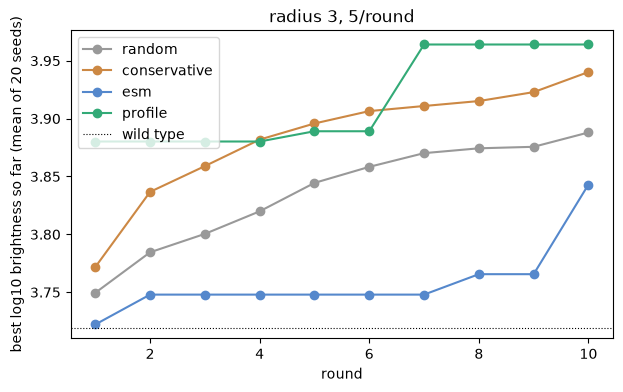

In [4]:
cfg = bakeoff.Config()
results = bakeoff.bakeoff(land, cfg, range(20))
fig, ax = plt.subplots(figsize=(7, 4))
colors = {"random": "#999", "conservative": "#c84", "esm": "#58c", "profile": "#3a7"}
for strategy, group in results.groupby("strategy", sort=False):
    curves = np.array(group.curve.tolist())
    ax.plot(range(1, cfg.rounds + 1), curves.mean(axis=0), "o-", label=strategy, color=colors[strategy])
ax.axhline(land.brightness[0], color="k", lw=0.8, ls=":", label="wild type")
ax.set(xlabel="round", ylabel="best log10 brightness so far (mean of 20 seeds)", title=f"radius {cfg.radius}, {cfg.proposals}/round")
ax.legend()
bakeoff.summarize(results)